In [1]:
#import random
import torch as tc
import numpy as np
import qutip as qt
import pandas as pd
import matplotlib.pyplot as plt
import torch.nn as nn
import time as tm
from torch.func import jacrev, vmap
from tqdm import tqdm
import sys
import os
sys.path.insert(0, '../src')
import function as my

# Set this to the number of physical cores you will use
num_threads = 10
tc.set_num_threads(num_threads)
tc.set_num_interop_threads(num_threads)
print(f"Threads set to: {tc.get_num_threads()}")

Threads set to: 10


In [2]:
tfinal      = 1.0
N           = 501
Nedo=12
Nfield=1
t_points =  np.linspace(tfinal/N,tfinal, N)

In [ ]:
def inv_sigmoid(y):
    eps = 1e-6
    y = tc.clamp(y, eps, 1 - eps)
    return tc.log(y / (1 - y))

class FourierFeatures(nn.Module):
    # Uncomment the following code to use uniform frequency distribution and comment the code below it
    """
    def __init__(self, n_freq, f_max, trainable=True):
        super().__init__()
        self.f_max = f_max
        self.raw_freq = nn.Parameter(tc.randn(n_freq), requires_grad=trainable)

        f0 = tc.linspace(0.05 * f_max, 0.95 * f_max, n_freq)
        raw0 = inv_sigmoid(f0 / f_max)

        self.raw_freq = nn.Parameter(raw0.clone(), requires_grad=trainable)

    def get_freq(self):
        return self.f_max * tc.sigmoid(self.raw_freq)

    def forward(self, t):
        if t.dim() == 1:
            t = t.unsqueeze(1)   # (batch,1)

        freq = self.get_freq().unsqueeze(0)   # (1,n_freq)
        arg = 2.0 * np.pi * t * freq        # (batch,n_freq)

        return tc.cat([tc.sin(arg), tc.cos(arg)], dim=1)
    """
    def __init__(self, m, sigma=10.0, trainable=False):
        super().__init__()
        B = tc.randn(m, 1) * sigma
        self.B = nn.Parameter(B, requires_grad=trainable)

    def forward(self, t):
        if t.dim() == 1:
            t = t[:, None]
        x = 2 * np.pi * t @ self.B.T
        return tc.cat([tc.sin(x), tc.cos(x)], dim=-1)
    
class Rede(nn.Module):
    def __init__(self, neuronio, activation, input_=1, output_=1,
                 creat_p=False, N_of_paramater=1, dropout_prob=0.0,
                 use_fourier=False, n_freq=32, f_max=10.0, trainable=True):
        super().__init__()

        self.neuronio = neuronio
        self.output = output_
        self.creat_p = creat_p
        self.N_of_paramater = N_of_paramater
        self.dropout_prob = dropout_prob
        self.use_fourier = use_fourier

        if use_fourier:
            #self.ff = FourierFeatures(n_freq=n_freq, f_max=f_max, trainable=True)
            self.ff = FourierFeatures(m=n_freq, sigma=f_max, trainable=trainable)
            first_in = 2 * n_freq
        else:
            self.ff = None
            first_in = input_

        self.hidden_layers = nn.ModuleList([nn.Linear(first_in, neuronio[0])])
        self.hidden_layers.extend(
            [nn.Linear(neuronio[_], neuronio[_+1]) for _ in range(len(neuronio)-1)]
        )
        self.output_layer = nn.Linear(neuronio[-1], output_)

        self.activation_ = activation
        self.dropouts = nn.ModuleList([nn.Dropout(dropout_prob) for _ in range(len(neuronio))])

        if creat_p:
            self.parametro = nn.Parameter(tc.rand(N_of_paramater))

    def forward(self, x):
        if self.ff is not None:
            x = self.ff(x)

        for layer, activation, dropout in zip(self.hidden_layers, self.activation_, self.dropouts):
            x = activation(layer(x))
            x = dropout(x)

        x = self.output_layer(x)
        return x
    
class SIN(tc.nn.Module):
    def __init__(self):
        super(SIN, self).__init__()
    def forward(self, x):
        return tc.sin(x)

Run this cell if you are using the above NN class, with the frequency trick. Run the next one otherwise.

In [ ]:
neuronio = [128, 128]

X_vector = Rede(
    neuronio=neuronio,
    input_=1,
    output_=Nedo + Nfield,
    activation=[SIN()]*len(neuronio),
    creat_p=True,
    N_of_paramater=0,
    use_fourier=True,
    n_freq=16,
    f_max=10.0,
    trainable=True
)

opt = tc.optim.Adam(X_vector.parameters(),
        lr = 0.001)
time =  tc.linspace(
        0,
        tfinal,
        N,
        dtype   = tc.float32,
        requires_grad = True).reshape((-1, 1))

In [3]:
neuronio = [256, 256, 256]#[128,128,128] didn't work
X_vector   = my.Rede(
    neuronio    = neuronio,
    input_      = 1,
    output_     = Nedo+Nfield,
    activation  =[tc.nn.Tanh()]*len(neuronio),
    creat_p     =True,
    N_of_paramater= 0)
opt = tc.optim.Adam(X_vector.parameters(),
        lr = 0.001)
time =  tc.linspace(
        0,
        tfinal,
        N,
        dtype   = tc.float32,
        requires_grad = True).reshape((-1, 1))
#index_data = np.random.randint(0,N,size=100)
#X_vector.parametro

In [5]:
@tc.jit.script
def calculate_total_loss(time: tc.Tensor, s0: tc.Tensor, s1: tc.Tensor, v0: tc.Tensor, vt: tc.Tensor, derivs: tc.Tensor, wt: tc.Tensor):
    """
    s0 : (N,6)  normalised state column 0  [I00 I10 I20 R00 R10 R20]
    s1 : (N,6)  normalised state column 1  [I01 I11 I21 R01 R11 R21]
    wt : (N,1)  control field
    """
    # On-site energies & couplings
    E  = tc.tensor([0., 10., 50.], device=time.device, dtype=s0.dtype)       # (3,)
    W  = tc.tensor([[0.,  1., 3.],                            # coupling matrix (symmetric)
                    [1.,  0., 5.],
                    [3.,  5., 0.]], device=time.device, dtype=s0.dtype)       # (3,3)
    
    #W  = tc.tensor([[0.,  1., 0.],                            # coupling matrix (symmetric)
    #                [1.,  0., 0.],
    #                [0.,  0., 0.]], device=time.device, dtype=s0.dtype)

    # Hamiltonian matrix H(t) = diag(E) + wt * W          — (N,3,3)
    H = E.diag().unsqueeze(0) + wt.float().unsqueeze(-1) * W                      # (N,3,3)

    # Stack both columns: psi has shape (N, 2, 6)
    # Split into imaginary [0:3] and real [3:6] parts
    I = tc.stack([s0[:, :3], s1[:, :3]], dim=1)               # (N,2,3)
    R = tc.stack([s0[:, 3:], s1[:, 3:]], dim=1)               # (N,2,3)

    # Schrödinger eqs:  dI/dt = -H @ R ,  dR/dt = H @ I
    # H @ X  for both columns at once:  (N,1,3,3) @ (N,2,3,1) → (N,2,3,1)
    HR = tc.matmul(H.unsqueeze(1), R.unsqueeze(-1)).squeeze(-1)   # (N,2,3)
    HI = tc.matmul(H.unsqueeze(1), I.unsqueeze(-1)).squeeze(-1)   # (N,2,3)

    rhs_I = -HR          # dI/dt target   (N,2,3)
    rhs_R =  HI          # dR/dt target   (N,2,3)

    # Reshape derivs to match [I, R] × [col0, col1] layout
    dI = tc.stack([derivs[:, 0:3], derivs[:, 6:9]],  dim=1)   # (N,2,3)
    dR = tc.stack([derivs[:, 3:6], derivs[:, 9:12]], dim=1)    # (N,2,3)

    # Residual squared, summed over all components
    loss_edo = ((dI - rhs_I)**2 + (dR - rhs_R)**2).mean()

    # ---- gate fidelity loss -----------------------------------------------
    # Fst ordering: [R00 R10 R20 R01 R11 R21 | I00 I10 I20 I01 I11 I21] at t=-1
    Fst = tc.cat([s0[-1, 3:], s1[-1, 3:],      # real parts   (6,)
                s0[-1, :3], s1[-1, :3]])       # imag parts   (6,)
    
    tauR = (Fst[:6] * vt[:6] + Fst[6:] * vt[6:]).sum()
    tauI = (Fst[6:] * vt[:6] - Fst[:6] * vt[6:]).sum()
    
    LOSS_gate = tc.abs(1.0 - 0.5*tauR)# Maybe a tc.abs()
    #LOSS_gate = tc.abs(1.0 - (tauR**2 + tauI**2)/4)
    
    # ---- initial-condition loss -------------------------------------------
    psi0 = tc.cat([s0[0, 3:], s1[0, 3:],        # real parts at t=0
                s0[0, :3], s1[0, :3]])        # imag parts at t=0
    
    # I WILL TRY WITH USING THE CORRECT EXPRESSION FOR
    # (1/2) \sum_{j=1}^N || |\psi_j(0)> - |\phi_j^(init)> ||^2
    # = N/2 + \sum_{j=1}^N {<\psi_j(0)|\psi_j(0)>/2 - Re[<\psi_j(0)|\phi_j^(init)>]}
    #Note that Re[<V|W>] = <Vr|Wr> + <Vi|Wi>, if |V> = |Vr> + i |Vi> (same for |W>)
    LOSS_data = tc.abs(1. - 0.5*tc.dot(psi0, v0))#1. + tc.dot(psi0, psi0)/2
    #LOSS_data = ((psi0 - v0)**2).sum()    # scalar (same as .mean() on a 0-d / 1-element)
    
    # ---- leakage / state loss ---------------------------------------------
    # |ψ₂|² for both columns: I20²+R20² + I21²+R21²
    Loss_state = (s0[:, 2]**2 + s0[:, 5]**2 +
                s1[:, 2]**2 + s1[:, 5]**2).mean()

    return loss_edo, LOSS_data, LOSS_gate, Loss_state

#calculate_physics_loss = tc.compile(calculate_physics_loss)

In [4]:
datfile = pd.read_csv('../PopsCtrl/Data/OptFieldKr_X_GATE_3levs_q03.csv')
#datfile = pd.read_csv('../PopsCtrl/Data/OptFieldKr_Had_GATE_3levs_alp2.csv')
#datfile = pd.read_csv('../PopsCtrl/Data/OptFieldKr_S_GATE_3levs_alp1c5.csv')
ctrl = (datfile.iloc[::20, 1:]).to_numpy().copy()
ctrl.shape

(501, 1)

Pre-training to fit the network output corresponding to the control field to the chosen guess field. Idea: do the same for the outputs corresponding to the states for them to fit the dynamics under the guess field.

In [6]:
def quevol(w_opt, t_points, instates):
    zero = qt.basis(3, 0)
    one = qt.basis(3, 1)
    two = qt.basis(3, 2)

    sig00 = zero * zero.dag()   # |0><0|
    sig11 =one *one.dag()    # |1><1|
    sig22 = two * two.dag()
    sig01 = zero * one.dag()   # |0><1|
    sig02 = zero * two.dag() # |0><2|
    sig12 = one * two.dag()   # |1><2|
    sig21 = two * one.dag() # |2><1|
    sig10 = one *zero.dag()   # |1><0|
    sig20 = two *zero.dag() # |2><0|

    E1=10;E2=50
    w01=1;w02=3;w12=5
    #w01=1;w02=0;w12=0
    H0 = E1*sig11+E2*sig22
    H1 = w01*(sig01+sig10)+w02*(sig02+sig20)+w12*(sig12+sig21)
    # The full Hamiltonian is defined as a list: 
    H = [H0, [H1, w_opt]] # QuTiP uses cubic spline interpolation for field_data
    #H = [H0, [H1, ctrl.flatten()]]

    # 3. Define the initial state and expectation value operators
    e_ops = [sig00, sig11, sig22] # Operators for which to calculate expectation values

    dim = 3
    opts = {'store_states':True, 'rtol':1.e-6, 'atol':1.e-8}
    for i in range(2):
        psi0 = instates[i]# + qt.basis(3, 1)).unit() # Initial state |0>
        # 4. Simulate the time evolution
        result = qt.sesolve(H, psi0, t_points, e_ops=e_ops, options=opts)
        if i==0:
            imst1 = np.array([[
                psi.full().flatten()[n].imag
                for psi in result.states
            ] for n in range(dim)])
            rest1 = np.array([[
                psi.full().flatten()[n].real
                for psi in result.states
            ] for n in range(dim)])
        else:
            imst2 = np.array([[
                psi.full().flatten()[n].imag
                for psi in result.states
            ] for n in range(dim)])
            rest2 = np.array([[
                psi.full().flatten()[n].real
                for psi in result.states
            ] for n in range(dim)])

    sts = np.vstack((imst1, rest1, imst2, rest2))
    sts = sts.T

    return sts


In [53]:
pi=tc.tensor([np.pi])
def guess_field(t):
    return pi/tfinal*tc.exp(-(t/tfinal-1/2)**2)*tc.cos(2*pi*10*t)

w_opt = guess_field(tc.from_numpy(t_points)).detach().numpy()
instates = [qt.basis(3,0), qt.basis(3,1)]
sts = quevol(w_opt, t_points, instates)

100%|██████████████████████████████████████| 1000/1000 [00:03<00:00, 321.36it/s]


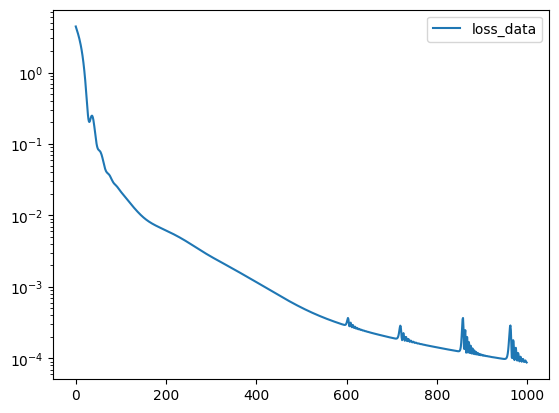

In [54]:
epocas  = 1000
LOSS    = []
LOSS1   = []
LOSS2   = []

for _ in tqdm(range(epocas)):
    ####### Forward pass #######
    y  = X_vector(time)
    LOSS_data =  (y[:,0:12] - tc.from_numpy(sts))**2

    LOSS_data += (y[:,12:13]- tc.from_numpy(w_opt).reshape(-1, 1))**2# guess_field(time)
    LOSS_data = LOSS_data.mean()
    
    ####### Loss total #######
    loss_i =  LOSS_data.mean()

    ####### Backpropagation #######
    opt.zero_grad()
    loss_i.backward()
    opt.step()
    LOSS2.append(LOSS_data.cpu().detach().numpy())
    LOSS.append(loss_i.cpu().detach().numpy())


plt.plot(LOSS2,label="loss_data")
plt.yscale("log")
plt.legend()
plt.show()


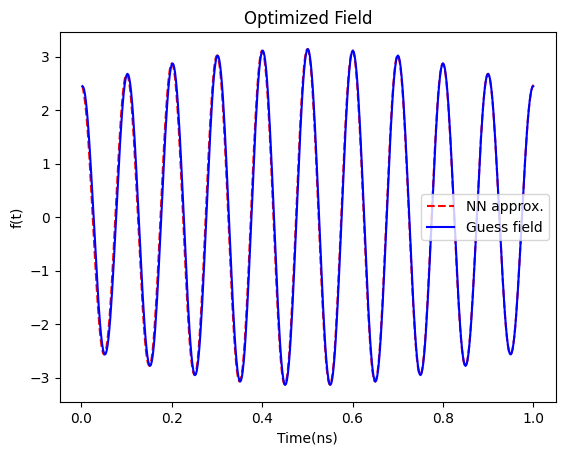

In [55]:
t_points =  np.linspace(tfinal/N,tfinal, N)
X_  = X_vector(time).detach().numpy()
w_opt=wt = tc.from_numpy(X_[:,-1])
plt.plot(t_points,w_opt,"r--", label="NN approx.")
plt.xlabel('Time(ns)')
plt.ylabel('f(t)')
plt.plot(t_points, guess_field(time).detach().numpy(),"b-", label="Guess field")
#plt.plot(t_points, ctrl,"b-", label="Guess field")
plt.legend()
plt.title('Optimized Field')
plt.show()

100%|█████████████████████████████████████| 10000/10000 [07:02<00:00, 23.67it/s]


Final value of the functional:  0.0044215724826790394
Number of iterations:  10000
Elapsed time: 422.4179569778498 s


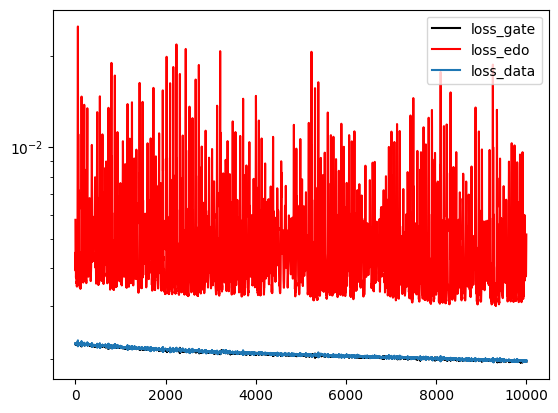

In [ ]:
epocas  = 10000
sqrt2=1.0/tc.sqrt(tc.Tensor([2.0]))
LOSS    = []
LOSS1   = []
LOSS2   = []

#The order is R00, R10, R20, R01, R11, R21, I00, I10, I20, I01, I11, I21
v0=tc.zeros(Nedo)
v0[0] = 1.;v0[4] = 1.
vt = tc.zeros(Nedo)

#X gate
#vt[1] = 1.;vt[3] = 1.

#H gate
# This struggles to converge when including the leakage term in the loss function
#vt[0] = sqrt2;vt[1] = sqrt2;vt[3] = sqrt2;vt[4] = -sqrt2

#S gate
#vt[0] = 1.;vt[10] = 1.
v0[0] = sqrt2;v0[6] =sqrt2;v0[4] = sqrt2;v0[10] = -sqrt2
vt[0] = sqrt2;vt[6] = sqrt2;vt[4] = sqrt2;vt[10] = sqrt2

def model_fn(t):
    return X_vector(t)

t_start = tm.perf_counter()
k = 0
err = 1.
navr = 200
avrerr = np.ones(navr, dtype=float)

for epoca in tqdm(range(epocas)):
#while(err > 5.e-3 and k < epocas):
    ####### Forward pass #######
    y  = X_vector(time)

    # Use vmap and jacrev to compute the Jacobian for every point in 'time' at once
    # This is significantly faster on both CPU and GPU
    #dN_dt_full = vmap(jacrev(model_fn))(time) 
 
    # You'll need to squeeze it:
    #dN_dt = dN_dt_full.squeeze()[:, :Nedo]

    # ---- split & normalise ------------------------------------------------
    state0 = y[:, :6]                  # (N,6)  I00 I10 I20 R00 R10 R20
    state1 = y[:, 6:12]               # (N,6)  I01 I11 I21 R01 R11 R21
    wt     = y[:, 12:13]              # (N,1)
    #wt = tc.from_numpy(ctrl)
    
    norma  = tc.sqrt((state0**2).sum(1, keepdim=True) + 1e-8)   # (N,1)
    norma1 = tc.sqrt((state1**2).sum(1, keepdim=True) + 1e-8)   # (N,1)
    
    s0 = state0 / norma               # (N,6) normalised
    s1 = state1 / norma1              # (N,6) normalised
    
    # keep the same 13-tuple interface for calculate_physics_loss
    regys = (*s0.split(1, dim=1), *s1.split(1, dim=1), wt)

    # If time is (N,1), autograd returns (N,1); expand via the Jacobian trick:
    # We still need per-component derivatives, so keep the loop-free cat approach:
    vars_list = list(s0.split(1, dim=1)) + list(s1.split(1, dim=1))  # 12 × (N,1)
    derivs = tc.cat(
        [tc.autograd.grad(v, time, grad_outputs=tc.ones_like(v),
                          create_graph=True)[0] for v in vars_list],
        dim=1,
    )
    
    #Loss_freq = ((tc.autograd.grad(wt, time, grad_outputs=tc.ones_like(wt), create_graph=True)[0])**2).sum()
    
    LOSS_edo, LOSS_data, LOSS_gate, Loss_state = calculate_total_loss(time, s0, s1, v0, vt, derivs, wt)
    ####### Loss total #######
    loss_i = LOSS_edo + LOSS_data + LOSS_gate + 0.3*Loss_state
    ####### Backpropagation #######
    opt.zero_grad()
    loss_i.backward()
    opt.step()
    LOSS1.append(LOSS_edo.cpu().detach().numpy())
    LOSS2.append(LOSS_data.cpu().detach().numpy())
    LOSS.append(LOSS_gate.cpu().detach().numpy())
    err = LOSS_edo.cpu().detach().numpy()#loss_i.cpu().detach().numpy()
    avrerr[k%navr] = err
    err = avrerr.mean()
    k += 1

t_end = tm.perf_counter()
tempo_total = t_end - t_start

print("Final value of the functional: ", err)
print("Number of iterations: ", k)
print(f"Elapsed time: {tempo_total} s")

plt.plot(LOSS,"k-",label="loss_gate")
plt.plot(LOSS1,'r-',label="loss_edo")
plt.plot(LOSS2,label="loss_data")
plt.yscale("log")
plt.legend()
plt.show()


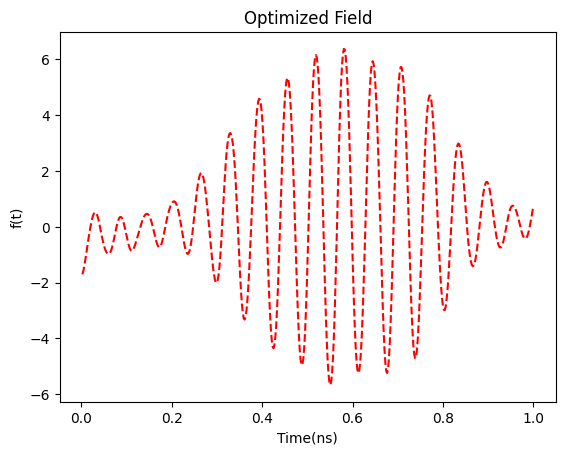

In [62]:
t_points =  np.linspace(tfinal/N,tfinal, N)
X_  = X_vector(time).detach().numpy()
#nor = np.sqrt(np.sum(X_[:,:6]**2))
#X_[:,:6] = X_[:,:6]/nor
w_opt=X_[:,-1]
plt.plot(t_points,w_opt,"r--")#, label="NN approx.")
plt.xlabel('Time(ns)')
plt.ylabel('f(t)')
#plt.plot(t_points, guess_field(time).detach().numpy(),"b-", label="Guess field")
#plt.legend()
plt.title('Optimized Field')
plt.show()

In [8]:
norma=np.sqrt(np.sum(X_[:,:6]**2, axis=1))
print(X_[-1,:6]/norma[-1])
norma1=np.sqrt(np.sum(X_[:,6:]**2, axis=1))
print(X_[-1,6:]/norma1[-1])


[0.6428826  0.58412004 0.1587135  0.32861382 0.3180681  0.10564797]
[ 0.50900596 -0.51145613 -0.05218522  0.21993093 -0.24249572 -0.03147182
 -0.60699093]


In [63]:
instates = [qt.basis(3,0), qt.basis(3,1)]
#instates = [(qt.basis(3,0)+ qt.basis(3,1)).unit(), (qt.basis(3,0)- qt.basis(3,1)).unit()]
sts = quevol(w_opt, t_points, instates)

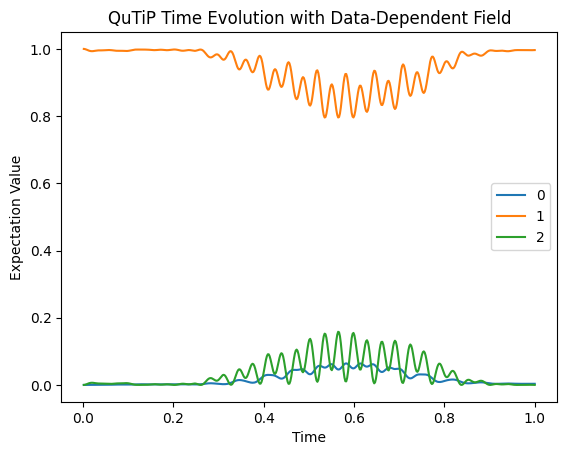

In [65]:
# 5. Plot the results
selst = 1
#norsq = np.sum(X_[:,:6]**2, axis=1) if selst==0 else np.sum(X_[:,6:12]**2, axis=1)
plt.figure()
#plt.plot(t_points, (X_[:,0+6*selst]**2+X_[:,3+6*selst]**2)/norsq.flatten(), '--', label='NN-0')
#plt.plot(t_points, (X_[:,1+6*selst]**2+X_[:,4+6*selst]**2)/norsq.flatten(), '--', label='NN-1')
#plt.plot(t_points, (X_[:,2+6*selst]**2+X_[:,5+6*selst]**2)/norsq.flatten(), '--', label='NN-2')

plt.plot(t_points, (sts[:,3+6*selst]**2 + sts[:,6*selst]**2), label='0')
plt.plot(t_points, (sts[:,4+6*selst]**2 + sts[:,1+6*selst]**2), label='1')
plt.plot(t_points, (sts[:,5+6*selst]**2 + sts[:,2+6*selst]**2), label='2')

#plt.plot(t_points,(X_[:,0]**2+X_[:,2]**2)/norma)
#plt.plot(t_points,(X_[:,1]**2+X_[:,3]**2)/norma)
plt.xlabel('Time')
plt.ylabel('Expectation Value')
plt.legend()
plt.title('QuTiP Time Evolution with Data-Dependent Field')
plt.show()

In [60]:
lev=0
print(f"1st state's pop. at |1>: {sts[-1,lev+3]**2 + sts[-1,lev]**2}")
print(f"2nd state's pop. at |0>: {sts[-1,lev+9]**2 + sts[-1,lev+6]**2}")

1st state's pop. at |1>: 0.9979830144254319
2nd state's pop. at |0>: 0.001975744015235914


In [66]:
merged = np.vstack((t_points, w_opt))    
df_from_numpy = pd.DataFrame(merged.T)

# Exporting the NumPy-based DataFrame
df_from_numpy.to_csv('../../PopsCtrl/Data/OptField_PINN_S_GATE_3L_FF_Ist_obliq.csv', index=False, header=['Time'] + ['Field'])